## Treinando $y=x^2$

In [ ]:
import torch
import numpy as np
from kan import KAN, create_dataset
import matplotlib.pyplot as plt

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 4.40e-03 | test_loss: 4.38e-03 | reg: 1.38e+01 | : 100%|█| 50/50 [00:23<00:00,  2.11it


saving model version 0.1


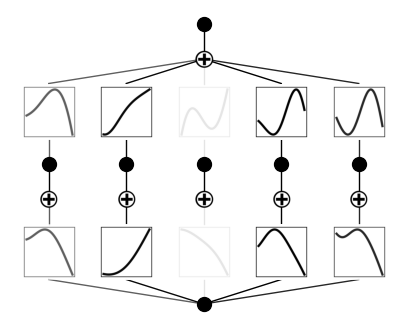

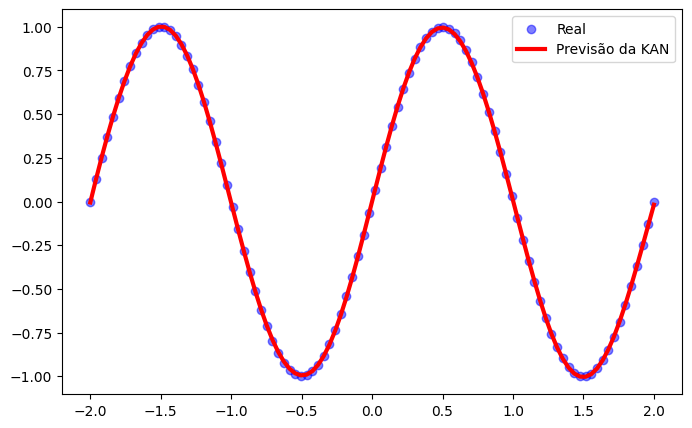

In [59]:
f = lambda x: np.sin(np.pi*x[:, [0]]) 

random = np.random.randint(0,1e8)
dataset = create_dataset(f, n_var=1, ranges=[-2, 2], train_num=500, test_num=500, seed = random)

# print(dataset['train_input'])
# print(dataset['train_label'])


# print(dataset['test_input'])
# print(dataset['test_label'])

model = KAN(width=[1, 5, 1], grid=5, k=12)

results = model.fit(dataset, opt="LBFGS", steps=50)

model.plot()

x_test = torch.linspace(-2, 2, 100).unsqueeze(1)
y_test = f(x_test)

with torch.no_grad():
    y_pred = model(x_test)

plt.figure(figsize=(8, 5))
plt.scatter(x_test.numpy(), y_test.numpy(), color="blue", label="Real", alpha=0.5)
plt.plot(x_test.numpy(), y_pred.numpy(), color="red", linewidth=3, label="Previsão da KAN")
plt.legend()
plt.show()